# 03 - Sistema Especialista (Regras SE-ENTÃO)

**Atividade 2 - DCT1401 Inteligência Artificial (UFRN, 2026.2)**

Neste notebook o conhecimento sobre risco cardiovascular é convertido em regras
SE-ENTÃO (Aula 05).

- **Base de conhecimento:** `rules/regras_classificacao.txt` e `rules/regras_regressao.txt`
  (texto puro, editável sem mexer no código).
- **Motor de inferência:** `src/expert_system.py`, encadeamento para frente
  (*forward chaining*), resolução de conflito pela ordem das regras e refração
  (cada regra dispara no máximo uma vez por paciente).
- Cada regra é classificada como **relação, recomendação, diretriz, estratégia ou
  heurística** (Durkin, 1994) e não mistura E com OU.
- As regras foram elaboradas **somente com o conjunto de treino**. O teste não é
  carregado aqui; ele só é usado na avaliação final (notebook 06).
- As regras foram redigidas com auxílio de IA generativa, a partir das tabelas de apoio
  abaixo; a justificativa de cada regra está comentada nos arquivos de regras. As sessões
  de inserção estão registradas em `logs/cronometro_regras.csv`. As medições computacionais de inferência estão no
  notebook 08.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import ARQUIVO_REGRAS, LOGS, TARGETS, carregar_split, salvar_fig, salvar_tabela
from src.expert_system import BaseConhecimento, MotorInferencia
from src.metrics import metricas_classificacao, metricas_regressao

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 120)

# Apenas TREINO (o conjunto de teste é descartado com "_").
Xc, _, yc, _ = carregar_split("classificacao")
Xr, _, yr, _ = carregar_split("regressao")
print("Treino classificação:", Xc.shape, "| Treino regressão:", Xr.shape)

Treino classificação: (7200, 30) | Treino regressão: (7200, 30)


## 1. Apoio à elaboração das regras (somente treino)

Tabelas descritivas usadas como evidência para escrever as regras: taxa de doença
(classificação) e média da FC máxima (regressão) por faixa (quartis) de cada variável.
Nenhum algoritmo de aprendizado de máquina gera regras: as faixas e limiares foram
propostos com auxílio de IA generativa a partir destas tabelas e de conhecimento
clínico (ex.: fórmula de Tanaka, angina induzida por exercício, depressão do segmento ST).

In [2]:
def resumo_por_faixa(X, y, col, q=4):
    """Média do alvo por quartil (variáveis contínuas) ou por valor (binárias)."""
    x = X[col]
    grupos = x if x.nunique() <= 2 else pd.qcut(x, q, duplicates="drop")
    return y.groupby(grupos, observed=True).agg(["mean", "count"])


def ranking(X, y):
    """Ordena as variáveis pela amplitude da média do alvo entre as faixas."""
    linhas = []
    for col in X.columns:
        r = resumo_por_faixa(X, y, col)["mean"]
        linhas.append({"variavel": col, "min_faixa": r.min(), "max_faixa": r.max(),
                       "amplitude": r.max() - r.min()})
    return pd.DataFrame(linhas).sort_values("amplitude", ascending=False).reset_index(drop=True)


print(f"Taxa de doença no treino: {yc.mean():.1%}")
rank_c = ranking(Xc, yc)
salvar_tabela(rank_c, "es_apoio_classificacao", index=False)
rank_c.head(12)

Taxa de doença no treino: 30.3%


,variavel,min_faixa,max_faixa,amplitude
0,max_heart_rate_achieved,0.028027,0.716991,0.688964
1,exercise_induced_angina,0.190269,0.676242,0.485972
2,st_depression,0.169114,0.560569,0.391454
3,age,0.145426,0.498515,0.353089
4,ldl,0.154416,0.470927,0.316511
5,hdl,0.167271,0.457068,0.289798
6,resting_bp_systolic,0.177618,0.463415,0.285797
7,exercise_minutes_per_week,0.171206,0.456379,0.285173
8,hba1c,0.176972,0.457538,0.280566
9,bmi,0.186122,0.430415,0.244294


In [3]:
for col in rank_c["variavel"].head(8):
    print(f"\n== {col} ==")
    print(resumo_por_faixa(Xc, yc, col).rename(columns={"mean": "taxa_doenca", "count": "n"}).round(3))


== max_heart_rate_achieved ==
                         taxa_doenca     n
max_heart_rate_achieved                   
(92.999, 150.0]                0.717  1848
(150.0, 166.0]                 0.315  1842
(166.0, 180.0]                 0.131  1726
(180.0, 210.0]                 0.028  1784

== exercise_induced_angina ==
                         taxa_doenca     n
exercise_induced_angina                   
0                              0.190  5529
1                              0.676  1671

== st_depression ==
               taxa_doenca     n
st_depression                   
(-0.001, 0.4]        0.169  2247
(0.4, 0.7]           0.233  1425
(0.7, 1.4]           0.295  1910
(1.4, 6.5]           0.561  1618

== age ==
                taxa_doenca     n
age                              
(17.999, 45.0]        0.145  1891
(45.0, 54.0]          0.248  1759
(54.0, 63.0]          0.338  1867
(63.0, 90.0]          0.499  1683

== ldl ==
                taxa_doenca     n
ldl                          

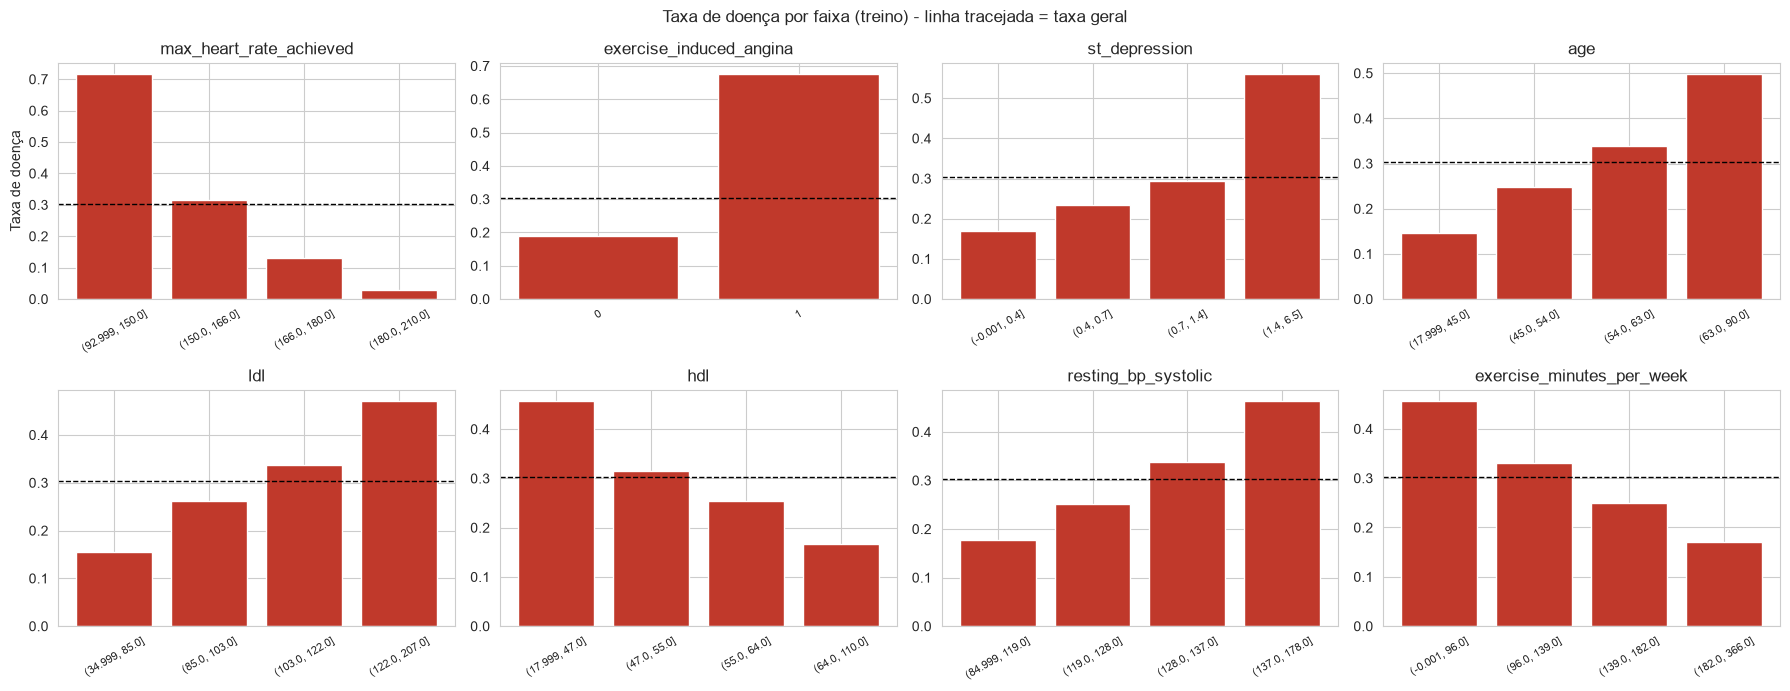

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), rank_c["variavel"].head(8)):
    r = resumo_por_faixa(Xc, yc, col)["mean"]
    ax.bar([str(i) for i in r.index], r.values, color="#c0392b")
    ax.axhline(yc.mean(), ls="--", c="k", lw=1)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
axes[0, 0].set_ylabel("Taxa de doença")
plt.suptitle("Taxa de doença por faixa (treino) - linha tracejada = taxa geral")
plt.tight_layout()
salvar_fig("es_apoio_classificacao")
plt.show()

In [5]:
print(f"FC máxima no treino: média {yr.mean():.1f} bpm, desvio {yr.std():.1f} bpm")
rank_r = ranking(Xr, yr)
salvar_tabela(rank_r, "es_apoio_regressao", index=False)
rank_r.head(12)

FC máxima no treino: média 164.9 bpm, desvio 21.3 bpm


,variavel,min_faixa,max_faixa,amplitude
0,age,143.717172,184.185616,40.468444
1,has_heart_disease,146.215857,173.030690,26.814833
2,resting_bp_systolic,154.381533,174.156571,19.775038
3,resting_bp_diastolic,156.451703,171.935980,15.484277
4,exercise_minutes_per_week,156.759542,172.035019,15.275477
5,exercise_induced_angina,155.248354,167.822572,12.574218
6,hba1c,158.545095,169.609808,11.064713
7,ldl,159.591825,170.355896,10.764071
8,daily_steps,159.753889,170.192222,10.438333
9,fasting_blood_sugar,159.441296,169.261400,9.820104


In [6]:
for col in rank_r["variavel"].head(8):
    print(f"\n== {col} ==")
    print(resumo_por_faixa(Xr, yr, col).rename(columns={"mean": "fc_media", "count": "n"}).round(1))


== age ==
                fc_media     n
age                           
(17.999, 45.0]     184.2  1891
(45.0, 54.0]       170.3  1759
(54.0, 63.0]       159.4  1867
(63.0, 90.0]       143.7  1683

== has_heart_disease ==
                   fc_media     n
has_heart_disease                
0                     173.0  5018
1                     146.2  2182

== resting_bp_systolic ==
                     fc_media     n
resting_bp_systolic                
(84.999, 119.0]         174.2  1948
(119.0, 128.0]          167.6  1791
(128.0, 137.0]          162.2  1739
(137.0, 178.0]          154.4  1722

== resting_bp_diastolic ==
                      fc_media     n
resting_bp_diastolic                
(49.999, 74.0]           171.9  2015
(74.0, 81.0]             167.0  1793
(81.0, 88.0]             163.2  1601
(88.0, 126.0]            156.5  1791

== exercise_minutes_per_week ==
                           fc_media     n
exercise_minutes_per_week                
(-0.001, 96.0]                15

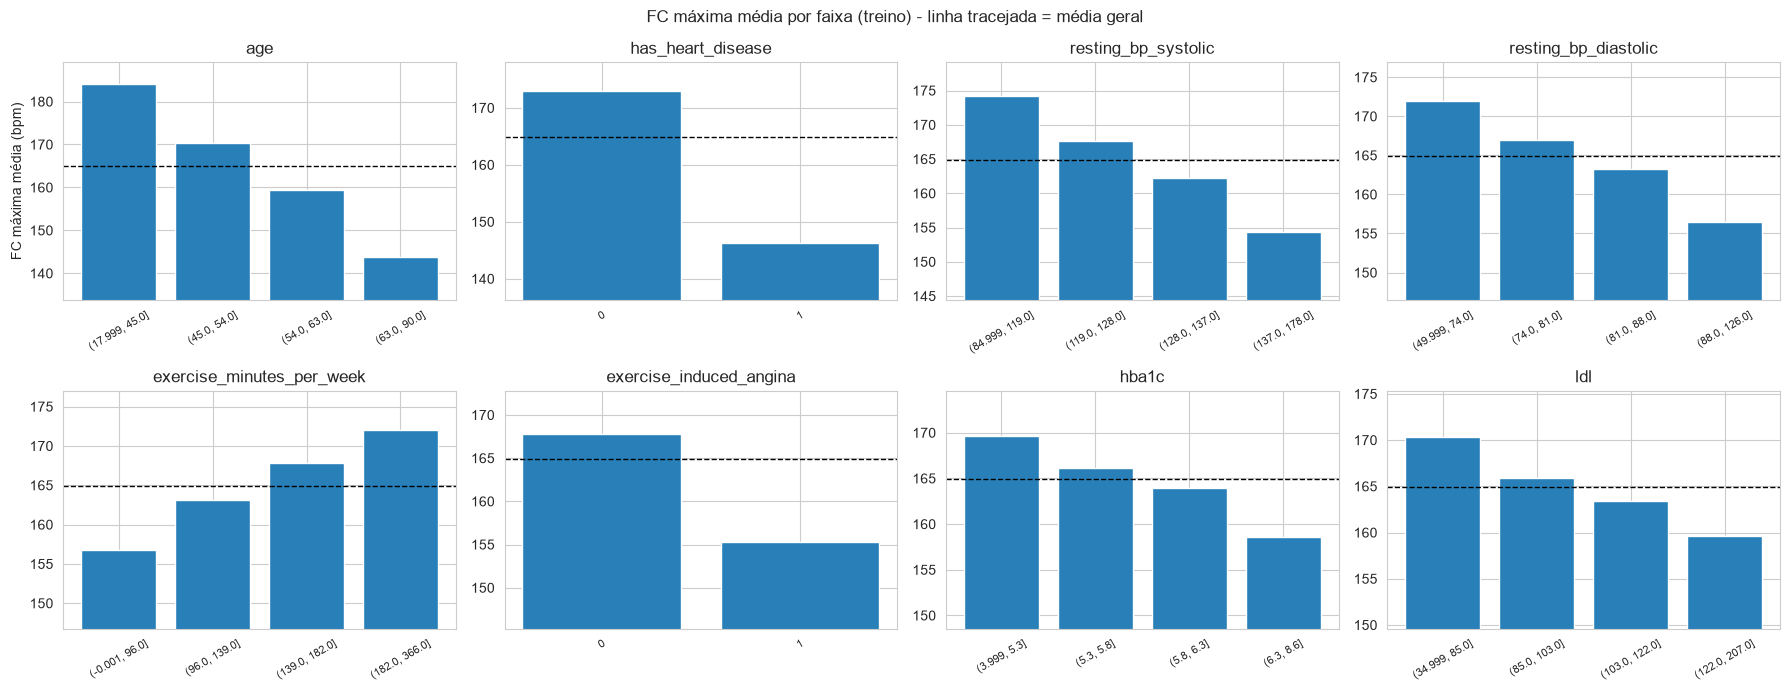

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), rank_r["variavel"].head(8)):
    r = resumo_por_faixa(Xr, yr, col)["mean"]
    ax.bar([str(i) for i in r.index], r.values, color="#2980b9")
    ax.axhline(yr.mean(), ls="--", c="k", lw=1)
    ax.set_ylim(r.min() - 10, r.max() + 5)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
axes[0, 0].set_ylabel("FC máxima média (bpm)")
plt.suptitle("FC máxima média por faixa (treino) - linha tracejada = média geral")
plt.tight_layout()
salvar_fig("es_apoio_regressao")
plt.show()

## 2. Bases de conhecimento

In [8]:
bases = {p: BaseConhecimento.de_arquivo(ARQUIVO_REGRAS[p]) for p in ARQUIVO_REGRAS}
for problema, base in bases.items():
    print(f"\n### {problema.upper()} - {len(base)} regras | padrões: {base.padroes}")
    tabela = pd.DataFrame([{"id": r.id, "tipo": r.tipo, "regra": r.texto.split("|", 2)[2].strip()}
                           for r in base.regras], columns=["id", "tipo", "regra"])
    salvar_tabela(tabela, f"es_regras_{problema}", index=False)
    display(tabela)
    if len(base):
        display(tabela["tipo"].value_counts().rename("n_regras").to_frame())


### REGRESSAO - 9 regras | padrões: {'max_heart_rate_achieved': 164.9}


,id,tipo,regra
0,R01,relacao,SE age > 0 ENTAO max_heart_rate_achieved = 208 - 0.7 * age
1,R02,relacao,SE has_heart_disease == 1 ENTAO max_heart_rate_achieved += -15
2,R03,relacao,SE exercise_induced_angina == 1 ENTAO max_heart_rate_achieved += -5
3,R04,recomendacao,SE exercise_minutes_per_week >= 190 ENTAO max_heart_rate_achieved += 5
4,R05,recomendacao,SE exercise_minutes_per_week <= 85 ENTAO max_heart_rate_achieved += -5
5,R06,heuristica,SE age <= 40 ENTAO max_heart_rate_achieved += 8
6,R07,heuristica,SE age >= 41 E age <= 50 ENTAO max_heart_rate_achieved += 4
7,R08,heuristica,SE age >= 61 E age <= 70 ENTAO max_heart_rate_achieved += -6
8,R09,heuristica,SE age >= 71 ENTAO max_heart_rate_achieved += -10


,n_regras
tipo,
heuristica,4
relacao,3
recomendacao,2



### CLASSIFICACAO - 14 regras | padrões: {'has_heart_disease': 0.0}


,id,tipo,regra
0,R01,relacao,SE exercise_induced_angina == 1 ENTAO score += 0.35
1,R02,relacao,SE st_depression >= 1.5 ENTAO score += 0.25
2,R03,relacao,SE max_heart_rate_achieved <= 147 ENTAO score += 0.3
3,R04,relacao,SE max_heart_rate_achieved >= 184 ENTAO score += -0.3
4,R05,relacao,SE age >= 65 ENTAO score += 0.15
5,R06,relacao,SE hdl <= 45 ENTAO score += 0.15
6,R07,relacao,SE ldl >= 126 ENTAO score += 0.15
7,R08,relacao,SE resting_bp_systolic >= 140 ENTAO score += 0.15
8,R09,relacao,SE smoker_Current == 1 ENTAO score += 0.15
9,R10,heuristica,SE hba1c >= 6.5 OU fasting_blood_sugar >= 140 ENTAO score += 0.1


,n_regras
tipo,
relacao,9
heuristica,5


## 3. Desempenho das regras no treino e cobertura

Avaliação apenas no treino, para orientar a elaboração. A avaliação no teste (final)
está no notebook 06.

In [9]:
motor_c = MotorInferencia(bases["classificacao"])
pred_c = motor_c.prever(Xc, TARGETS["classificacao"])
score_c = motor_c.pontuacao(Xc)
print("Classificação (treino):", {k: round(v, 4) for k, v in metricas_classificacao(yc, pred_c, score_c).items()})

motor_r = MotorInferencia(bases["regressao"])
pred_r = motor_r.prever(Xr, TARGETS["regressao"])
print("Regressão (treino):", {k: round(v, 4) for k, v in metricas_regressao(yr, pred_r).items()})

Classificação (treino): {'Accuracy': 0.8419, 'Precision': 0.7225, 'Recall': 0.7768, 'F1': 0.7487, 'ROC-AUC': 0.9041, 'PR-AUC': 0.8171}
Regressão (treino): {'MAE': 9.8186, 'MSE': 152.0604, 'RMSE': np.float64(12.3313), 'MAPE (%)': 6.0721, 'R2': 0.6634, 'MedAE': 8.3}


In [10]:
for problema, motor, X in [("classificacao", motor_c, Xc), ("regressao", motor_r, Xr)]:
    if len(motor.base):
        cob = pd.Series(motor.cobertura(X), name="fracao_disparos")
        print(f"\nCobertura das regras ({problema}, treino):")
        display(cob.round(3).to_frame().T)


Cobertura das regras (classificacao, treino):

,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12,R13,R99
fracao_disparos,0.232,0.225,0.215,0.203,0.211,0.212,0.208,0.194,0.172,0.229,0.196,0.275,0.099,0.326



Cobertura das regras (regressao, treino):


,R01,R02,R03,R04,R05,R06,R07,R08,R09
fracao_disparos,1.0,0.303,0.232,0.217,0.197,0.156,0.234,0.214,0.102


## 4. Cronometragem da elaboração das regras

Cada sessão registra os horários reais de início e fim. Como as regras foram geradas
por IA, o tempo mede só a inserção e a validação no treino, e não representa o esforço
de um especialista humano. Para cada problema: tempo de cada sessão, média por sessão, desvio padrão
(amostral) e tempo médio por regra (= tempo total / total de regras criadas).
Esse tempo **substitui o tempo de treinamento** apenas nesta família de modelos e
**não** é somado ao tempo de inferência.

In [11]:
log = pd.read_csv(LOGS / "cronometro_regras.csv")
display(log)

resumo = []
for problema, g in log.groupby("problema"):
    resumo.append({
        "problema": problema,
        "n_sessoes": len(g),
        "tempo_total_min": g["duracao_min"].sum(),
        "tempo_medio_sessao_min": g["duracao_min"].mean(),
        "desvio_padrao_min": g["duracao_min"].std(ddof=1),
        "n_regras_total": g["n_regras_criadas"].sum(),
        "tempo_medio_por_regra_min": g["duracao_min"].sum() / g["n_regras_criadas"].sum(),
    })
resumo = pd.DataFrame(resumo, columns=["problema", "n_sessoes", "tempo_total_min",
                                       "tempo_medio_sessao_min", "desvio_padrao_min",
                                       "n_regras_total", "tempo_medio_por_regra_min"])
salvar_tabela(resumo, "es_cronometragem_resumo", index=False)
if resumo.empty:
    print("Nenhuma sessão registrada em logs/cronometro_regras.csv.")
resumo.round(2)

,problema,sessao,data,hora_inicio,hora_fim,duracao_min,n_regras_criadas,interrupcoes,observacoes
0,classificacao,1,2026-10-25,23:55:39,23:55:57,0.30,5,0,Regras geradas por IA; validação
1,classificacao,2,2026-10-25,23:56:03,23:56:09,0.10,5,0,Regras geradas por IA; inserção + validação
2,classificacao,3,2026-10-25,23:56:14,23:56:21,0.12,4,0,Regras geradas por IA; inserção + validação
3,regressao,1,2026-10-25,23:56:24,23:56:36,0.20,1,0,Regras geradas por IA; inserção + validação
4,regressao,2,2026-10-25,23:56:40,23:56:48,0.13,4,0,Regras geradas por IA; inserção + validação
5,regressao,3,2026-10-25,23:56:53,23:57:00,0.12,4,0,Regras geradas por IA; inserção + validação


,problema,n_sessoes,tempo_total_min,tempo_medio_sessao_min,desvio_padrao_min,n_regras_total,tempo_medio_por_regra_min
0,classificacao,3,0.52,0.17,0.11,14,0.04
1,regressao,3,0.45,0.15,0.04,9,0.05


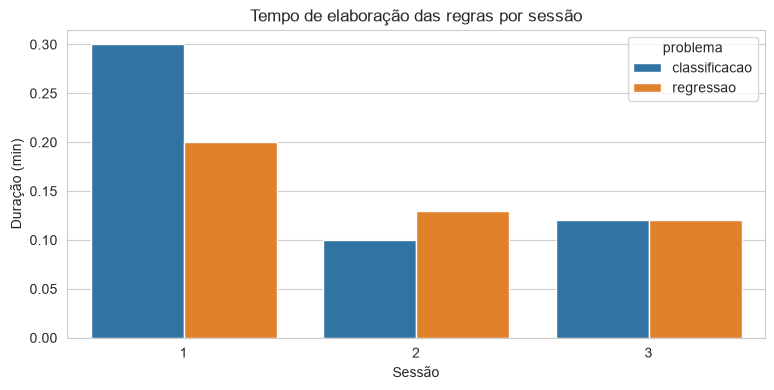

In [12]:
if not log.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.barplot(data=log, x="sessao", y="duracao_min", hue="problema", ax=ax)
    ax.set_xlabel("Sessão")
    ax.set_ylabel("Duração (min)")
    ax.set_title("Tempo de elaboração das regras por sessão")
    salvar_fig("es_cronometragem")
    plt.show()